# Session 06: Attribution and Logit Lens

**Student implementer and maintainer:** YQ-HA. This notebook records code typed,
executed, and adapted while following the instructor during class, together with
the student's post-course completions and maintenance.

**Course:** Tyler Shoemaker, [Introduction to Interpretability for Language Models](https://digitaltheorylab.github.io/2026_interpretability-reader/).
Reference implementation: [06_attribution.md](https://github.com/digitaltheorylab/2026_interpretability-reader/blob/main/chapters/06_attribution.md).

**Repair assistance:** OpenAI Codex assisted with locating and explaining errors,
restoring omitted course code, and checking coverage and runnability. `Repair:`
comments identify corrected mistakes; `Course completion:` comments identify
restored steps. Original classroom notes, including `##` comments, are retained.

Run from the first cell with the kernel in `notebooks/`. New results go to
`results/session-06/`. This repaired version awaits a new Colab run.


In [1]:
from pathlib import Path
import json
import platform
import sys
import matplotlib.pyplot as plt
PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results" / "session-06"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
FACET_HEIGHT = 4
FACET_ASPECT = 1.2
def save_figure(name):
    plt.gcf().savefig(RESULTS_DIR / name, bbox_inches="tight", dpi=150)
    plt.show()
    plt.close("all")


In [2]:
import re
from string import Template

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS
from sklearn.metrics import balanced_accuracy_score

In [3]:
SYSTEM_PROMPT = (
    "You are a literary classification assistant. "
    "Read the story and the answer options, then respond with the single "
    "letter of the option that best identifies the story's genre."
)

USER_TEMPLATE = Template(
    "Read the following story and identify its genre.\n\n====\n\n"
    "Story:\n$story\n\n====\n\n"
    "$options"
)

options = """
A) Horror
B) Detective fiction
C) Romance
D) Science fiction
E) Thriller
"""


In [4]:
df = pd.read_parquet(DATA_DIR / "w2-d2_genre-attributions.parquet")
df.head()


,story_id,true_genre,letter_to_genre,correct_letter,predicted_letter,prompt,tokens,token_offsets,input_ids,logits_by_layer,token_grads,story_token_mask
0,0,Detective fiction,"{'A': 'Thriller', 'B': 'Detective fiction', 'C...",B,D,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.384765625, -0.4609375, -0.46484375, -2.453...","[0.75, 0.44140625, 4.25, 0.9296875, 1.21875, 1...","[False, False, False, False, False, False, Fal..."
1,1,Detective fiction,"{'A': 'Thriller', 'B': 'Science fiction', 'C':...",E,D,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.310546875, -0.4453125, -0.55078125, -2.671...","[1.09375, 0.6640625, 6.625, 1.3125, 1.671875, ...","[False, False, False, False, False, False, Fal..."
2,2,Detective fiction,"{'A': 'Science fiction', 'B': 'Detective ficti...",B,D,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.18359375, -1.2421875, -1.140625, -2.578125...","[0.671875, 0.455078125, 4.28125, 0.859375, 1.0...","[False, False, False, False, False, False, Fal..."
3,3,Detective fiction,"{'A': 'Science fiction', 'B': 'Detective ficti...",B,D,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.609375, -0.25390625, -0.345703125, -1.9531...","[1.2265625, 0.69921875, 6.71875, 1.4375, 1.570...","[False, False, False, False, False, False, Fal..."
4,4,Detective fiction,"{'A': 'Thriller', 'B': 'Romance', 'C': 'Horror...",D,B,<|im_start|>system\nYou are a literary classif...,"[<|im_start|>, system, \n, You, are, a, lit...","[[0, 12], [12, 18], [18, 19], [19, 22], [22, 2...","[100264, 9125, 198, 2675, 527, 264, 32465, 247...","[[0.490234375, -0.80859375, -1.0625, -2.328125...","[1.890625, 0.9375, 9.4375, 2.828125, 2.3125, 2...","[False, False, False, False, False, False, Fal..."


In [5]:
df["letter_to_genre"].sample().item()


# Gradient Attribution: Where we assign a sensitivity score to all tokens w.r.t some signal.
# A gradient registers model internals w.r.t. signal.
#
# - Direction： given loss, the mode;'s weights should go in a certain direction (in vector)
# - Magnitude:: given loss, the direction should be "X" much.
#
# Instead of model weights, we're just going to look at tokens
# Simiplify the gradient signal by removing direction (sensitivity scoring)



# Grand objective:
# measure the difference between the correct-letter logit and the incorrect-letter logits.
#
# "read this story, then give it a genre label {A,B,C,D,E}"
#
# A B C D E
# x ^ x x x
#
# logit(B) - logsumexp(A,C,D,E)
#
# Under this setup, we of course could've picked any token. But which? How do you grab sth
# in the model and use it to build signal?
#
# --->>>> shap.readthedocs.io/en/latest/index.html
#
# If you have "actual" ("external") labels, this task becomes a lot easier, because you can
# be sure that the reference points for the signal are stable (more stable)

{'A': 'Science fiction',
 'B': 'Romance',
 'C': 'Thriller',
 'D': 'Detective fiction',
 'E': 'Horror'}

In [6]:
print(df["prompt"].sample().item())

<|im_start|>system
You are a literary classification assistant. Read the story and the answer options, then respond with the single letter of the option that best identifies the story's genre.<|im_end|>
<|im_start|>user
Read the following story and identify its genre.

====

Story:
The first time I heard the whisper, I was alone in the attic, dusting the old furniture. The house was old, and I had inherited it from my grandmother. I was twenty-two, and I had just finished my degree in psychology. I was living off student loans and the occasional odd job, and this house was supposed to be a safe haven.

The whisper came from the old rocking chair in the corner. It was a faint sound, almost like a sigh, but it was distinct enough to make me pause. I looked around, but there was no one there. I brushed it off as my imagination and continued dusting.

The next time I heard the whisper, I was in the kitchen, making coffee. It was louder this time, a clear and distinct sound that seemed to c

In [7]:
df["token_grads"][0]

array([0.75      , 0.44140625, 4.25      , ..., 3.1875    , 4.125     ,
       9.8125    ])

In [8]:
samp = df.sample()
samp
(
    samp
    .explode(["tokens", "token_grads"])
    .reset_index()
    .sort_values("token_grads", ascending=False)[["tokens", "token_grads"]]
    .head(15)
)


,tokens,token_grads
2081,\n,20.5
2056,),17.25
92,the,12.8125
2078,\n,12.3125
2075,),11.3125
2080,assistant,11.1875
11,the,10.9375
2,\n,10.8125
48,.\n\n,10.625
50,\n\n,10.1875


In [9]:
cruft = [
    "didn", "don", "doesn", "isn", "aren", "wasn", "weren", "hasn", "haven", 
    "hadn", "won", "wouldn", "couldn", "shouldn", "can", "mustn", "needn", 
    "shan", "mightn",
]

ENGLISH_STOP_WORDS = ENGLISH_STOP_WORDS | set(cruft)
        

In [10]:
RE_PATTERN = re.compile(r"(?u)\b[a-zA-Z]{3,}\b")

In [11]:
def aggregate_tokens(
    text, offsets, gradients, pattern, mask=None, stop_words=None
):
    """Aggregate and filter subword tokens.

    Uses a regular expression match to find word-like tokens in story text and
    filters those tokens via a stop word list.

    Parameters
    ----------
    text : str
        Story text
    offsets : np.ndarray
        Token offsets from the LLM tokenizer, shape (n_token, 2)
    gradients : np.ndarray
        Token gradients, shape (n_token,)
    pattern : re.Pattern
        Regular expression pattern for finding tokens
    mask : np.ndarray or None
        Story mask for ignoring prompt tokens, shape (n_token,)
    stop_words : iterable or None
        Stop word list

    Returns
    -------
    list[dict]
        Aggregated words with metadata:
        - word: combined token string
        - span_start: start of word span
        - span_end: end of word span
        - token_indices: token indices in word
        - subwords: individual tokens in token string
        - n_tokens: number of tokens in word
        - grad_sum: sum of token gradients
        - grad_mean: mean of token gradients
    """
    if mask is None:
        mask = np.ones(len(offsets), dtype=bool)
    
    if stop_words is None:
        stop_words = set()

    # Stack offsets so offsets[:, 0] == start, offsets[:, 1] == end
    offsets = np.vstack(offsets)
    assert len(mask) == len(offsets), "Mask length doesn't match offset length"

    output = []

    for match in pattern.finditer(text):
        word = match.group(0)
        span_start, span_end = match.span()

        # Ignore stopwords
        if word.lower() in stop_words:
            continue

        # Overlap if: token_start < span_end and token_end > span_start
        (overlapping,) = np.where(
            mask
            & (offsets[:, 0] < span_end)
            & (offsets[:, 1] > span_start)
            & (offsets[:, 1] > offsets[:, 0])
        )

        if len(overlapping) == 0:
            continue

        # Build our word from tokens
        subwords = []
        
        for i in overlapping:
            tok_start, tok_end = offsets[i]

            clipped_start = max(tok_start, span_start)
            clipped_end = min(tok_end, span_end)

            subwords.append(text[clipped_start:clipped_end])

        # Get token gradients
        grads = gradients[overlapping]

        # Construct metadata
        row = {
            "word": word,
            "span_start": span_start,
            "span_end": span_end,
            "token_indices": overlapping.tolist(),
            "subwords": subwords,
            "n_tokens": len(overlapping),
            "grad_sum": grads.sum(),
            "grad_mean": grads.mean(),
        }

        output.append(row)

    return output

In [12]:
def aggregate(row):
    """Helper function for using ``aggregate_tokens()`` on DataFrame rows.

    Parameters
    ----------
    row : pd.Series
        DataFrame row

    Returns
    -------
    pd.DataFrame
        Aggregated token DataFrame
    """
    agg = aggregate_tokens(
        text=row["prompt"].lower(),
        offsets=row["token_offsets"],
        gradients=row["token_grads"],
        pattern=RE_PATTERN,
        mask=row["story_token_mask"],
        stop_words=ENGLISH_STOP_WORDS,
    )

    # Convert to a DataFrame and assign some metadata
    agg = pd.DataFrame(agg)
    agg["story_id"] = row["story_id"]
    agg["genre"] = row["true_genre"]

    return agg

In [13]:
agg = df.apply(aggregate, axis=1)
agg = pd.concat(agg.tolist(), ignore_index=True)
print("Shape of aggregated words (n_word, n_feat):", agg.shape)

Shape of aggregated words (n_word, n_feat): (299444, 10)


In [14]:
agg.head()

,word,span_start,span_end,token_indices,subwords,n_tokens,grad_sum,grad_mean,story_id,genre
0,detective,283,292,"[53, 54]","[detect, ive]",2,2.011719,1.005859,0,Detective fiction
1,marlowe,293,300,"[55, 56, 57]","[mar, low, e]",3,3.214844,1.071615,0,Detective fiction
2,stood,301,306,[58],[stood],1,0.800781,0.800781,0,Detective fiction
3,door,319,323,[62],[door],1,0.996094,0.996094,0,Detective fiction
4,boarding,331,339,[65],[boarding],1,0.523438,0.523438,0,Detective fiction


In [15]:
indices = agg["story_id"].isin(samp["story_id"])

In [16]:
agg[indices].sort_values("grad_mean", ascending=False).head(10)


,word,span_start,span_end,token_indices,subwords,n_tokens,grad_sum,grad_mean,story_id,genre
186242,year,458,462,[93],[year],1,4.593750,4.593750,323,Science fiction
186244,solved,483,489,[101],[solved],1,3.640625,3.640625,323,Science fiction
186246,faster,505,511,[105],[faster],1,3.156250,3.156250,323,Science fiction
186236,commander,396,405,[80],[commander],1,2.359375,2.359375,323,Science fiction
186225,ship,287,291,[54],[ship],1,2.187500,2.187500,323,Science fiction
186661,inside,5453,5459,[1323],[inside],1,2.171875,2.171875,323,Science fiction
186226,dawnbreaker,293,304,"[56, 57, 58]","[d, awn, breaker]",3,6.335938,2.111979,323,Science fiction
186237,rina,406,410,"[81, 82]","[r, ina]",2,4.203125,2.101562,323,Science fiction
186243,union,473,478,[99],[union],1,2.093750,2.093750,323,Science fiction
186348,voice,1714,1719,[384],[voice],1,1.875000,1.875000,323,Science fiction


In [17]:
# Repair: Exclude words with no leave-one-genre-out comparison.
STORY_WORD_AGG = {
    "story_grad_sum": ("grad_mean", "sum"),  # Total gradient mass in story
    "story_grad_mean": ("grad_mean", "mean"),  # Avg. influence per occurrence
    "story_n": ("grad_mean", "size"),  # Num. word occurrences
}


GENRE_WORD_AGG = {
    "grad_mean_across_stories": ("story_grad_mean", "mean"),  # Avg. influence
    "grad_sum_across_stories": ("story_grad_sum", "sum"),  # Total gradient mass
    "n_stories": ("story_id", "size"),  # Num. stories each word appears
    "n_occurrences": ("story_n", "sum"),  # Total word occurrences
}


def distinctive_words(df, min_stories=10, top_n=25):
    """Get distinctive words per genre.

    Parameters
    ----------
    df : pd.DataFrame
        Aggregated word DataFrame for all stories in the dataset
    min_stories : int
        Minimum number of stories a word must appear in within a genre
    top_n : int
        Number of distinctive words to return per genre

    Returns
    -------
    pd.DataFrame
        Distinctive words per genre, ranked by genre_lift
    """
    # One row per story/genre/word
    story_word = (
        df
        .groupby(["story_id", "genre", "word"], as_index=False)
        .agg(**STORY_WORD_AGG)
    )

    # One row per genre/word
    genre_word = (
        story_word
        .groupby(["genre", "word"], as_index=False)
        .agg(**GENRE_WORD_AGG)
    )

    # Group words, then count the number of word occurences and unique words
    word_group = genre_word.groupby("word")
    word_sum = word_group["grad_mean_across_stories"].transform("sum")
    word_cnt = word_group["grad_mean_across_stories"].transform("count")

    # Subtract this genre's own value before averaging
    genre_word["global_grad_mean"] = (
        (word_sum - genre_word["grad_mean_across_stories"]) / (word_cnt - 1)
    )

    # Exclude words with no other observed genre: their comparator is undefined.
    genre_word = genre_word.loc[word_cnt > 1].copy()

    # Calculate lift
    genre_word["genre_lift"] = (
        genre_word["grad_mean_across_stories"] - genre_word["global_grad_mean"]
    )

    # Filter to words above min_stories and return the top lifted words
    return (
        genre_word
        .query("n_stories >= @min_stories")
        .sort_values(["genre", "genre_lift"], ascending=[True, False])
        .groupby("genre", group_keys=False)
        .head(top_n)
        .reset_index(drop=True)
    )

top_distinctive = distinctive_words(agg, min_stories=10, top_n=25)

In [18]:
# Course completion: Restore plotting constants before the first facet plot.
FACET_HEIGHT = 4
FACET_ASPECT = 1.2


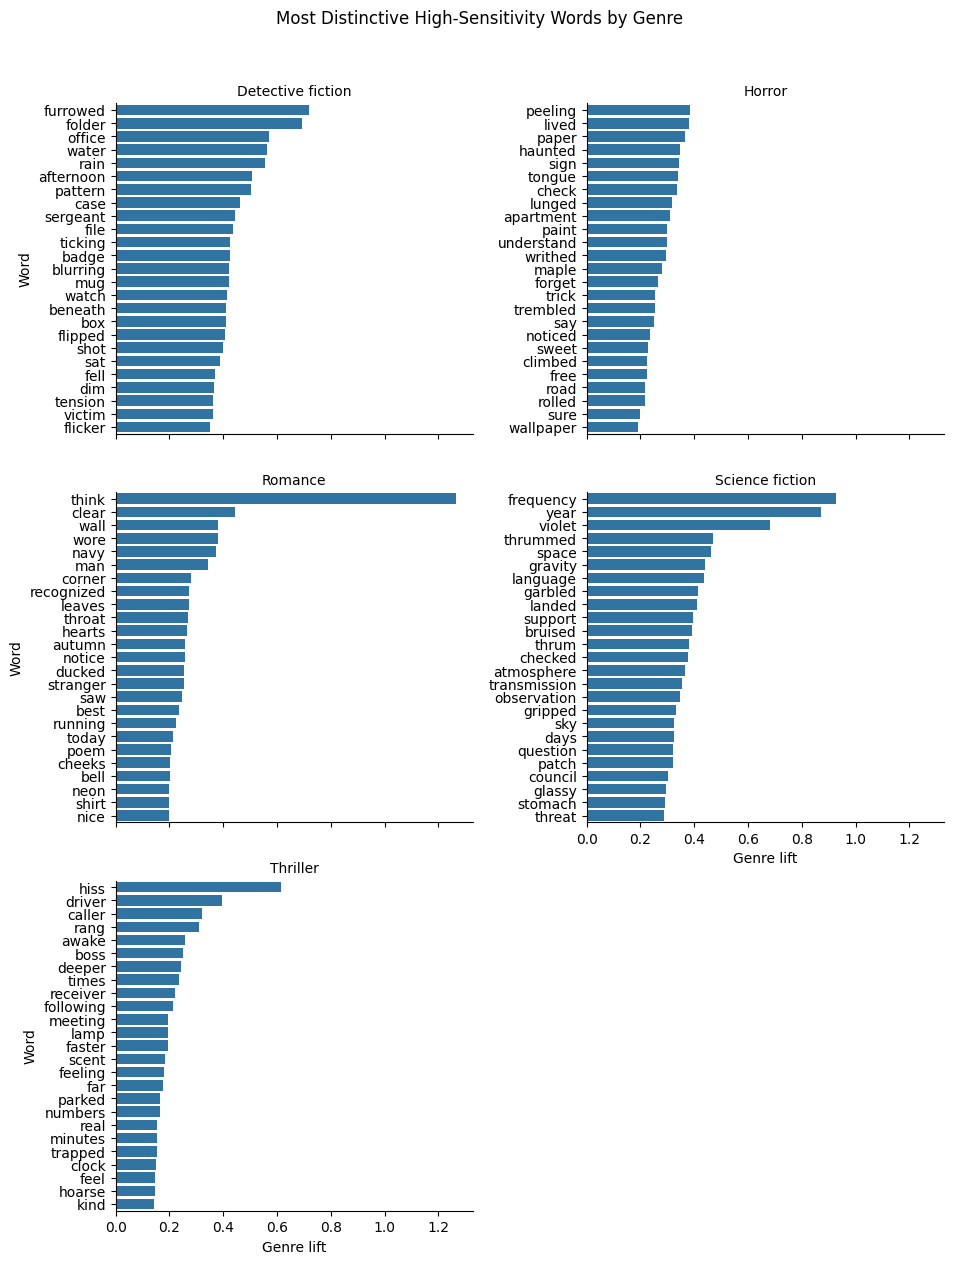

In [19]:
g = sns.catplot(
    data=top_distinctive,
    kind="bar",
    x="genre_lift",
    y="word",
    col="genre",
    col_wrap=2,
    sharey=False,
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.set_axis_labels("Genre lift", "Word")
g.set_titles("{col_name}")
g.fig.suptitle("Most Distinctive High-Sensitivity Words by Genre", y=1.05)
save_figure("s06-original-017.png")

In [20]:
y_true = df["correct_letter"]
y_pred = df["predicted_letter"]
df["correct"] = y_true == y_pred

mcqa_acc = balanced_accuracy_score(y_true, y_pred)
print(f"Letter/predicted letter accuracy: {100 * mcqa_acc:.2f}%")


Letter/predicted letter accuracy: 48.02%


In [21]:
# Logit lens to ask: can we see where this letter bias emerges?
#
# Logit lens is the model "readout" after each Transformer block in its architecture
#
# At layer(N), taken the hidden states (n_dim,) and run them through the final "unembedding" layer,
# which is shape (vocab_size); IN other words, if we had to predict a token after layer(N),
# what would the logit scores be for all tokens in the model vocabulary?
np.vstack(df["logits_by_layer"][0]).shape

(33, 5)

In [22]:
logit_matrix = np.vstack(samp["logits_by_layer"].item())
print("Number of layers:", logit_matrix.shape)

Number of layers: (33, 5)


In [23]:
# Repair: Use the LETTERS constant already defined in this cell.
LETTERS = list("ABCDE")
confusion_matrix = (
    pd.crosstab(y_true, y_pred).reindex(columns=LETTERS, index=LETTERS)
)

In [24]:
def layer_logits_to_frame(row):
    """Format a story's layer logits into a DataFrame.

    Parameters
    ----------
    row : pd.Series
        Story data, including genre/prediction metadata as well as logits

    Returns
    -------
    pd.DataFrame
        Logit DataFrame with columns:
        - layer: layer
        - genre: genre
        - correct_letter: correct label for genre
        - final_predicted_letter: final predicted letter
        - layer_predicted_letter: layer's genre prediction
        - layer_correct: whether the layer prediction is correct
        - matches_final_prediction: whether layer prediction matches final
        - correct_margin: margin between correct answer and next-best
        - [A..E]: logit for each letter label
    """
    logits = np.vstack(row["logits_by_layer"])
    n_layer = logits.shape[0]

    correct_idx = LETTERS.index(row["correct_letter"])
    pred_idx = logits.argmax(axis=1)
    layer_pred = np.asarray(LETTERS)[pred_idx]

    # Margin between the correct logit and the best competing logit
    correct_logit = logits[:, correct_idx]
    other_cols = np.arange(logits.shape[1]) != correct_idx
    correct_margin = correct_logit - logits[:, other_cols].max(axis=1)

    lens = pd.DataFrame({
        "layer": np.arange(n_layer),
        "genre": row["true_genre"],
        "correct_letter": row["correct_letter"],
        "final_predicted_letter": row["predicted_letter"],
        "layer_predicted_letter": layer_pred,
        "layer_correct": layer_pred == row["correct_letter"],
        "matches_final_prediction": layer_pred == row["predicted_letter"],
        "correct_margin": correct_margin,
    })

    for i, letter in enumerate(LETTERS):
        lens[letter] = logits[:, i]

    return lens

In [25]:
logit_lens = df.apply(layer_logits_to_frame, axis=1)
logit_lens = pd.concat(logit_lens.tolist(), ignore_index=True)
print("Logit lens shape:", logit_lens.shape)


Logit lens shape: (16500, 13)


In [26]:
logit_lens.head()

,layer,genre,correct_letter,final_predicted_letter,layer_predicted_letter,layer_correct,matches_final_prediction,correct_margin,A,B,C,D,E
0,0,Detective fiction,B,D,A,False,False,-0.845703,0.384766,-0.460938,-0.464844,-2.453125,-2.93750
1,1,Detective fiction,B,D,A,False,False,-0.467285,0.117676,-0.349609,-0.000706,-1.960938,-3.09375
2,2,Detective fiction,B,D,A,False,False,-1.197266,0.792969,-0.404297,-1.335938,-1.210938,-2.46875
3,3,Detective fiction,B,D,A,False,False,-2.359863,0.094238,-2.265625,-3.406250,-2.250000,-4.59375
4,4,Detective fiction,B,D,A,False,False,-0.910156,-0.503906,-1.414062,-1.812500,-2.734375,-4.81250


In [27]:
y_true = df["correct_letter"]
y_pred = df["predicted_letter"]
df["correct"] = y_true == y_pred

mcqa_acc = balanced_accuracy_score(y_true, y_pred)
print(f"Letter/predicted letter accuracy: {100 * mcqa_acc:.2f}%")

Letter/predicted letter accuracy: 48.02%


In [28]:
genre_acc = df.groupby("true_genre").agg(acc=("correct", "mean"))
genre_acc.reset_index(inplace=True)

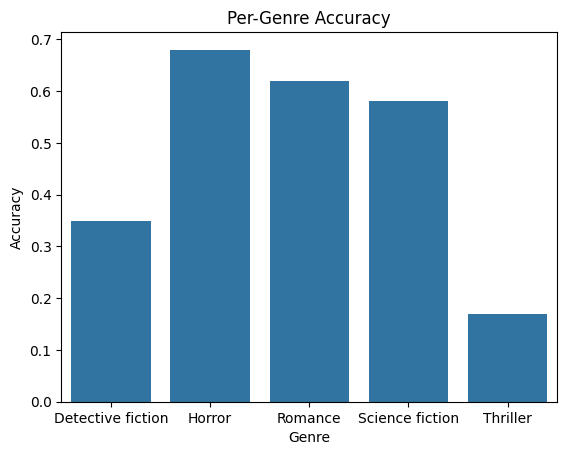

In [29]:
fig, ax = plt.subplots()
sns.barplot(data=genre_acc, x="true_genre", y="acc", ax=ax)
ax.set(title="Per-Genre Accuracy", xlabel="Genre", ylabel="Accuracy")
save_figure("s06-original-028.png")

In [30]:
letters = list("ABCDE")
confusion_matrix = (
    pd.crosstab(y_true, y_pred).reindex(columns=letters, index=letters)
)

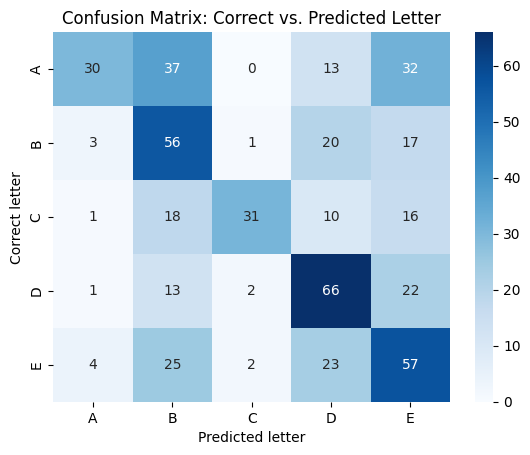

In [31]:
fig, ax = plt.subplots()
sns.heatmap(confusion_matrix, cmap="Blues", annot=True, fmt="d", ax=ax)
ax.set(
    title="Confusion Matrix: Correct vs. Predicted Letter",
    xlabel="Predicted letter",
    ylabel="Correct letter",
)
save_figure("s06-original-030.png")

In [32]:
LETTERS = list("ABCDE")

def letter_bias(true_col, pred_col):
    """Compare observed vs. expected wrong-letter choices.

    Parameters
    ----------
    true_col : pd.Series
        Correct letters
    pred_col : pd.Series
        Predicted letters

    Returns
    -------
    pd.DataFrame
        Per-letter excess_share: positive means the model overuses this letter
        when wrong, negative means it avoids it
    """
    confusion_matrix = (
        pd.crosstab(true_col, pred_col)
        .reindex(index=LETTERS, columns=LETTERS, fill_value=0)
    )

    # Keep only wrong predictions
    off = confusion_matrix.values.copy()
    np.fill_diagonal(off, 0)
    off = pd.DataFrame(off, index=LETTERS, columns=LETTERS)

    # Observed: how often each letter is chosen when wrong. Expected: each
    # row's errors spread evenly over the other k-1 letters
    k = len(LETTERS)
    observed = off.sum(axis=0)
    row_errors = off.sum(axis=1)
    total_errors = row_errors.sum()
    expected = (total_errors - row_errors) / (k - 1)

    bias = pd.DataFrame({"observed": observed, "expected": expected})

    if total_errors > 0:
        bias["observed_share"] = bias["observed"] / total_errors
        bias["expected_share"] = bias["expected"] / total_errors
    else:
        bias["observed_share"] = 0.0 
        bias["expected_share"] = 0.0

    bias["excess_share"] = bias["observed_share"] - bias["expected_share"]

    return bias.reset_index(names="predicted_letter")

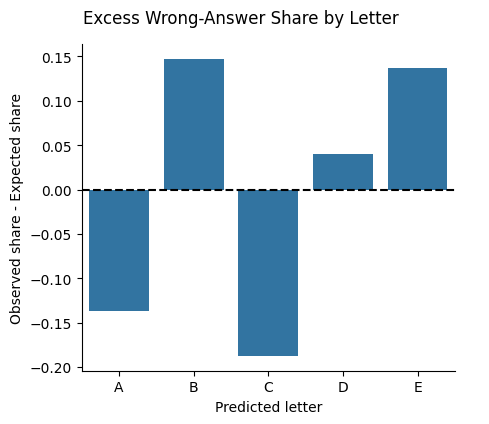

In [33]:
bias = letter_bias(y_true, y_pred)

g = sns.catplot(
    data=bias,
    kind="bar",
    x="predicted_letter",
    y="excess_share",
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.refline(y=0, linestyle="--", color="black")
g.set_axis_labels("Predicted letter", "Observed share - Expected share")
g.fig.suptitle("Excess Wrong-Answer Share by Letter", y=1.05)
save_figure("s06-original-032.png")

In [34]:
letter_bias_score = 0.5 * bias["excess_share"].abs().sum()
print(f"Overall letter-bias score: {letter_bias_score:.3f}")

Overall letter-bias score: 0.324


In [35]:
genre_layer_summary = (
    logit_lens
    .groupby(["genre", "layer"], as_index=False)
    .agg(
        correct_margin=("correct_margin", "mean"),
    )
)

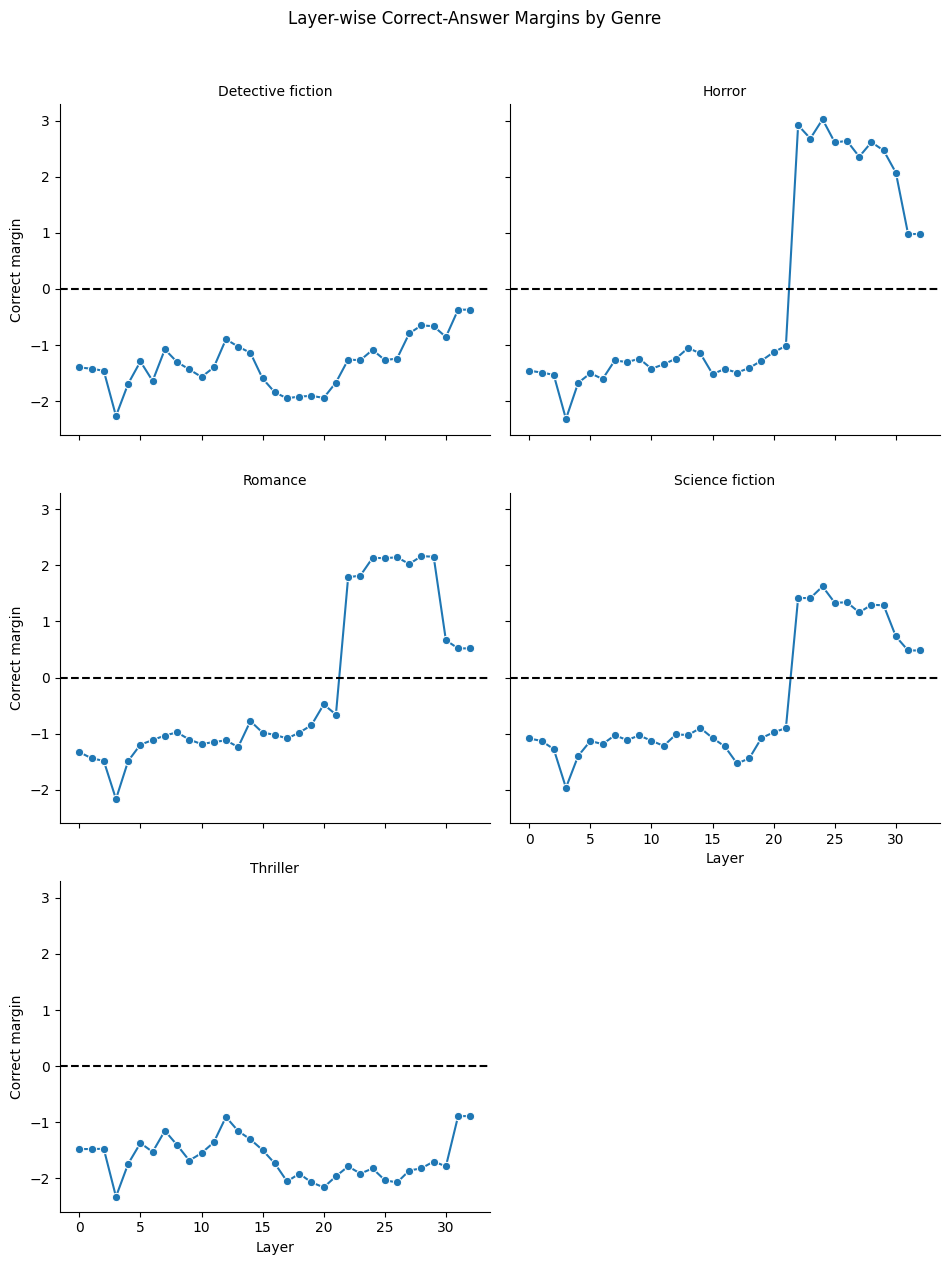

In [36]:
g = sns.relplot(
    data=genre_layer_summary,
    kind="line",
    x="layer",
    y="correct_margin",
    col="genre",
    col_wrap=2,
    marker="o",
    facet_kws={"sharey": True},
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.refline(y=0, linestyle="--", color="black")
g.set_axis_labels("Layer", "Correct margin")
g.set_titles("{col_name}")
g.fig.suptitle("Layer-wise Correct-Answer Margins by Genre", y=1.05)
save_figure("s06-original-035.png")

In [37]:
# Course completion: Restore layer-wise letter distribution, bias, and prediction-stability analysis.
letter_dist = pd.crosstab(
    logit_lens["layer"],
    logit_lens["layer_predicted_letter"],
    normalize="index",
)


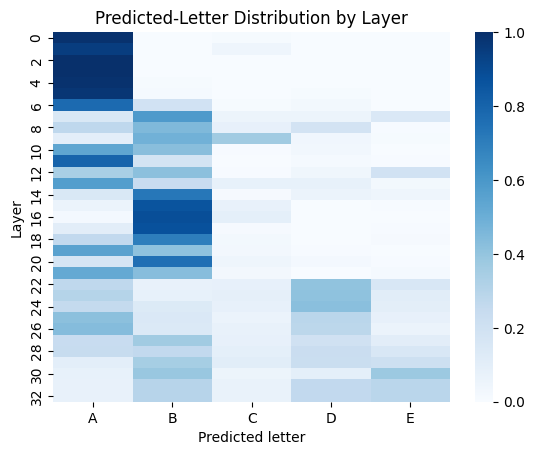

In [38]:
# Course completion: Restore layer-wise letter distribution, bias, and prediction-stability analysis.
fig, ax = plt.subplots()
sns.heatmap(letter_dist, cmap="Blues", vmin=0, vmax=1, ax=ax)
ax.set(
    title="Predicted-Letter Distribution by Layer",
    xlabel="Predicted letter",
    ylabel="Layer",
)
save_figure(RESULTS_DIR / "figure-06.png")


In [39]:
# Course completion: Restore layer-wise letter distribution, bias, and prediction-stability analysis.
bias_by_layer = []
for layer, layer_df in logit_lens.groupby("layer"):
    bias = letter_bias(
        layer_df["correct_letter"], layer_df["layer_predicted_letter"]
    )

    bias["layer"] = layer
    bias_by_layer.append(bias)

bias_by_layer = pd.concat(bias_by_layer, ignore_index=True)


In [40]:
# Course completion: Restore layer-wise letter distribution, bias, and prediction-stability analysis.
excess_plot = bias_by_layer.pivot(
    index="layer", columns="predicted_letter", values="excess_share",
)


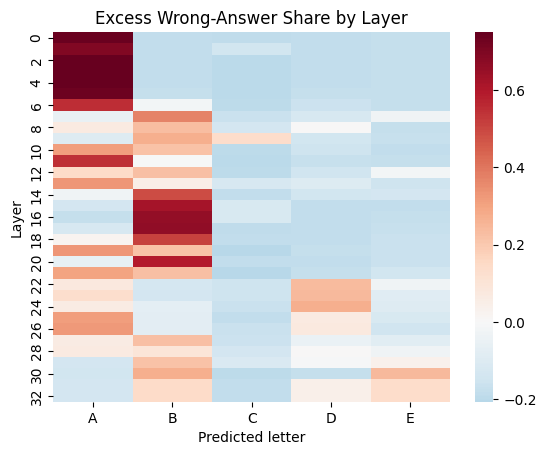

In [41]:
# Course completion: Restore layer-wise letter distribution, bias, and prediction-stability analysis.
fig, ax = plt.subplots()
sns.heatmap(excess_plot, cmap="RdBu_r", center=0, ax=ax)
ax.set(
    title="Excess Wrong-Answer Share by Layer",
    xlabel="Predicted letter",
    ylabel="Layer",
)
save_figure(RESULTS_DIR / "figure-07.png")


In [42]:
# Course completion: Restore layer-wise letter distribution, bias, and prediction-stability analysis.
layer_bias_score = (
    bias_by_layer
    .groupby("layer", as_index=False)
    .agg(letter_bias_score=("excess_share", lambda x: 0.5 * x.abs().sum()))
)

final_agreement = (
    logit_lens
    .groupby("layer", as_index=False)
    .agg(final_agreement=("matches_final_prediction", "mean"))
)

layer_dynamics = (
    layer_bias_score
    .merge(final_agreement, on="layer")
    .melt(id_vars="layer", var_name="measure", value_name="value")
)

layer_dynamics["measure"] = layer_dynamics["measure"].map({
    "letter_bias_score": "Letter-bias score",
    "final_agreement": "Agreement with final prediction",
})


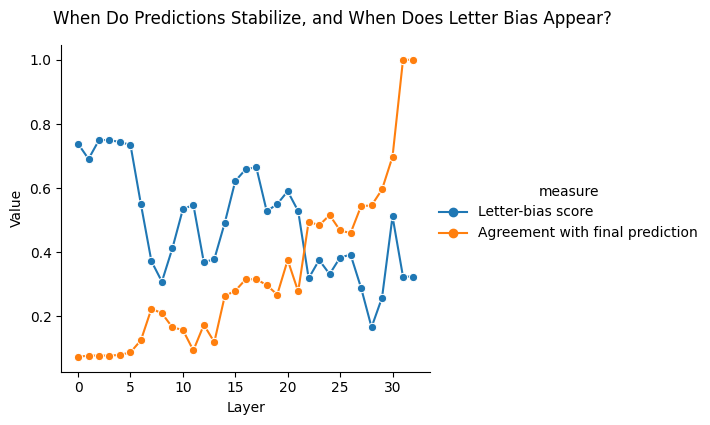

In [43]:
# Course completion: Restore layer-wise letter distribution, bias, and prediction-stability analysis.
g = sns.relplot(
    data=layer_dynamics,
    kind="line",
    x="layer",
    y="value",
    hue="measure",
    marker="o",
    height=FACET_HEIGHT,
    aspect=FACET_ASPECT,
)
g.set_axis_labels("Layer", "Value")
g.fig.suptitle(
    "When Do Predictions Stabilize, and When Does Letter Bias Appear?", y=1.05
)
save_figure(RESULTS_DIR / "figure-08.png")


In [44]:
top_distinctive.to_csv(RESULTS_DIR / "top_distinctive.csv", index=True)
genre_acc.to_csv(RESULTS_DIR / "genre_acc.csv", index=True)
genre_layer_summary.to_csv(RESULTS_DIR / "genre_layer_summary.csv", index=True)
bias_by_layer.to_csv(RESULTS_DIR / "bias_by_layer.csv", index=True)
layer_dynamics.to_csv(RESULTS_DIR / "layer_dynamics.csv", index=True)
observed = {name: module.__version__ for name, module in sys.modules.items()
            if name in {"numpy", "pandas", "torch", "transformers", "sklearn", "scipy", "matplotlib", "seaborn"}}
environment = {"python": platform.python_version(), "imported_packages": observed}
(RESULTS_DIR / "environment.json").write_text(json.dumps(environment, indent=2), encoding="utf-8")
print("Completed notebook; results:", RESULTS_DIR)


Completed notebook; results: /content/interpretability-classroom-notebooks/results/session-06
